In [1]:
%pip install diffrax

Note: you may need to restart the kernel to use updated packages.


In [2]:
# Real scalar boson star or oscillaton example
# see further details in https://github.com/GRChombo/engrenage/wiki/Running-the-oscillaton-example

# restart the kernel to clear past work
# (can also do this manually from the Kernel options above)
from IPython.core.display import HTML
HTML("<script>Jupyter.notebook.kernel.restart()</script>")

In [3]:
# load the required python modules
import numpy as np
from scipy.interpolate import interp1d
from scipy.integrate import odeint
from scipy.integrate import solve_ivp
import time
import random
import sys
from tqdm import tqdm
import matplotlib.pyplot as plt
%matplotlib inline

# homemade source code from source folder
sys.path.append('../source')

from core.grid import Grid
from core.rhsevolution import *
from core.spacing import *
from core.display import * 
from core.statevector import *
from matter.scalarmatter import *
from initialdata.oscillatoninitialconditions import *
from backgrounds.sphericalbackground import *
from bssn.constraintsdiagnostic import *

c:\Users\ipits\OneDrive - Queen Mary, University of London\Engrenage Work\engrenage-irene\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
# Set up the chosen matter class
scalar_mu = 1.0
my_matter = ScalarMatter(scalar_mu)
my_state_vector = StateVector(my_matter)

# Input parameters for grid and evolution here
r_max = 64 # outer edge of the grid (including ghosts)
min_dr = 1 / 4
max_dr = 2

# SinhSpacing
# params = SinhSpacing.get_parameters(r_max, min_dr, max_dr)
# spacing = SinhSpacing(**params)

# CubicSpacing
params = CubicSpacing.get_parameters(r_max, min_dr, max_dr)
spacing = CubicSpacing(**params)

grid = Grid(spacing, my_state_vector)
r = grid.r
num_points = r.size
background = FlatSphericalBackground(r)

# Check grid params
print(params)

{'r_max': 64, 'extent': <SpacingExtent.HALF: 0>, 'a': Array(7.25691788, dtype=float64, weak_type=True), 'num_points': 81}


In [5]:
import jax

# Make a fresh object using the updated ScalarMatter code
my_matter = ScalarMatter(scalar_mu)

# Check each numerical metadata field
for name in ["PARITY", "ASYMP_POWER", "ASYMP_OFFSET", "indices"]:
    value = getattr(my_matter, name)
    print(name, type(value), isinstance(value, jax.Array))

PARITY <class 'jaxlib._jax.ArrayImpl'> True
ASYMP_POWER <class 'jaxlib._jax.ArrayImpl'> True
ASYMP_OFFSET <class 'jaxlib._jax.ArrayImpl'> True
indices <class 'jaxlib._jax.ArrayImpl'> True


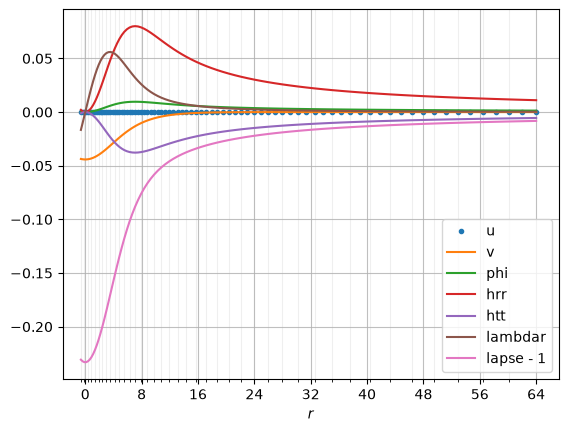

In [6]:
initial_state = get_initial_state(grid, background)

#unpackage the vector for readability
(initial_phi, initial_hrr, initial_htt, initial_hpp, 
 initial_K, initial_arr, initial_att, initial_app, 
 initial_lambdar, initial_shiftr, initial_br, initial_lapse,
 initial_u, initial_v) = np.array_split(initial_state, grid.NUM_VARS)

#plot initial conditions
plt.xlabel('r')
plt.plot(r, initial_u, '.', label='u') # zero, but plot as dots to see the grid
plt.plot(r, initial_v, label='v')
plt.plot(r, initial_phi, label='phi')
plt.plot(r, initial_hrr, label='hrr')
plt.plot(r, initial_htt, label='htt')
plt.plot(r, initial_lambdar, label='lambdar')
#plt.plot(r, initial_shiftr, label='shiftr')
plt.plot(r, initial_lapse-1, label='lapse - 1')
plt.legend(loc='best')
ax = plt.gcf().gca()
set_grid_on_ax(ax, r)
#plt.xlim(-0.25,5.0)
#plt.ylim(-0.0005,0.0005)

In [7]:
rhs0 = get_rhs(
    0.0,
    jnp.asarray(initial_state),
    grid,
    background,
    my_matter,
)

print("RHS shape:", rhs0.shape)
print("Initial state shape:", initial_state.shape)
print("Is a JAX array:", isinstance(rhs0, jax.Array))

RHS shape: (1134,)
Initial state shape: (1134,)
Is a JAX array: True


In [8]:
import diffrax as dfx

In [9]:
# Take 10 small steps for this first test
dt_test = 0.1 * float(grid.min_dr)
t_end_test = 10.0 * dt_test

def rhs_for_diffrax(t, state, args):
    return get_rhs(t, state, grid, background, my_matter)

solution_test = dfx.diffeqsolve(
    terms=dfx.ODETerm(rhs_for_diffrax),
    solver=dfx.Dopri5(),
    t0=0.0,
    t1=t_end_test,
    dt0=dt_test,
    y0=jnp.asarray(initial_state),
    saveat=dfx.SaveAt(ts=jnp.array([0.0, t_end_test])),
    stepsize_controller=dfx.ConstantStepSize(),
    max_steps=100,
)

print("Saved solution shape:", solution_test.ys.shape)
print("Is a JAX array:", isinstance(solution_test.ys, jax.Array))

Saved solution shape: (2, 1134)
Is a JAX array: True


In [10]:
T = 10.0
num_points_t = 101
output_dt = T / num_points_t

# Same output times as the old SciPy run
ts = jnp.linspace(0.0, T - output_dt, num_points_t)

# Keep the same maximum step-size limit
max_step = 0.4 * float(grid.min_dr)

diffrax_solution = dfx.diffeqsolve(
    terms=dfx.ODETerm(rhs_for_diffrax),
    solver=dfx.Dopri5(),
    t0=0.0,
    t1=T,
    dt0=max_step,
    y0=jnp.asarray(initial_state),
    saveat=dfx.SaveAt(ts=ts),
    stepsize_controller=dfx.PIDController(
        rtol=1e-3,
        atol=1e-6,
        dtmax=max_step,
    ),
    max_steps=100_000,
)

print("Saved solution shape:", diffrax_solution.ys.shape)
print("Saved time shape:", diffrax_solution.ts.shape)

Saved solution shape: (101, 1134)
Saved time shape: (101,)


In [11]:
import numpy as np

np.savez(
    "oscillaton_diffrax_result.npz",
    times=np.asarray(diffrax_solution.ts),
    states=np.asarray(diffrax_solution.ys),
)

In [12]:
numpy_run = np.load("oscillaton_numpy_result.npz")
diffrax_run = np.load("oscillaton_diffrax_result.npz")

numpy_times = numpy_run["times"]
numpy_states = numpy_run["states"]
diffrax_times = diffrax_run["times"]
diffrax_states = diffrax_run["states"]

print("Shapes:", numpy_states.shape, diffrax_states.shape)
print("Maximum time difference:",
      np.max(np.abs(numpy_times - diffrax_times)))
print("Maximum state difference:",
      np.max(np.abs(numpy_states - diffrax_states)))

Shapes: (101, 1134) (101, 1134)
Maximum time difference: 0.0
Maximum state difference: 1.4926943018401437e-08


In [13]:
from core.spacing import NUM_GHOSTS

def final_u_norm(A):
    # Reshape the initial state into (variables, grid points)
    state0 = jnp.asarray(initial_state).reshape(
        grid.NUM_VARS, grid.N
    )

    # Temporarily scale the scalar matter data by A
    state0 = state0.at[my_matter.idx_u].set(
        A * state0[my_matter.idx_u]
    )
    state0 = state0.at[my_matter.idx_v].set(
        A * state0[my_matter.idx_v]
    )

    # Flatten it back to the format expected by get_rhs
    state0 = state0.reshape(-1)

    # Evolve for the same short test interval
    sol = dfx.diffeqsolve(
        terms=dfx.ODETerm(rhs_for_diffrax),
        solver=dfx.Dopri5(),
        t0=0.0,
        t1=t_end_test,
        dt0=dt_test,
        y0=state0,
        saveat=dfx.SaveAt(t1=True),
        stepsize_controller=dfx.ConstantStepSize(),
        max_steps=100,
    )

    # Return one simple number from the final scalar field
    final_state = sol.ys[0].reshape(grid.NUM_VARS, grid.N)
    u = final_state[
        my_matter.idx_u, NUM_GHOSTS:-NUM_GHOSTS
    ]
    return jnp.sum(u**2)


A = 1.0
print("Diagnostic:", final_u_norm(A))
print("JAX gradient:", jax.grad(final_u_norm)(A))

Diagnostic: 0.0010600863517026121
JAX gradient: 0.0021187957679268963


In [14]:
A = 1.0
eps = 1e-4

gradient_ad = jax.grad(final_u_norm)(A)
gradient_fd = (
    final_u_norm(A + eps) - final_u_norm(A - eps)
) / (2 * eps)

print("JAX gradient:", gradient_ad)
print("Finite-difference estimate:", gradient_fd)
print(
    "Relative difference:",
    abs(gradient_ad - gradient_fd) / abs(gradient_fd),
)

JAX gradient: 0.0021187957679268963
Finite-difference estimate: 0.0021187957679016153
Relative difference: 1.1931774152156936e-11


In [15]:
from pathlib import Path
import numpy as np

comparison_dir = Path(
    r"C:\Users\ipits\OneDrive - Queen Mary, University of London\Engrenage Work\engrenage-irene\trials"
)

# Save the JAX results for comparison.
np.save(comparison_dir / "initial_state_jax.npy", np.asarray(initial_state))
np.save(comparison_dir / "r_jax.npy", np.asarray(grid.r))

# Load the NumPy results saved from the original version.
state_numpy = np.load(comparison_dir / "initial_state_numpy.npy")
r_numpy = np.load(comparison_dir / "r_numpy.npy")

# Load the JAX results we just saved.
state_jax = np.load(comparison_dir / "initial_state_jax.npy")
r_jax = np.load(comparison_dir / "r_jax.npy")

print("Grid shapes:", r_numpy.shape, r_jax.shape)
print("State shapes:", state_numpy.shape, state_jax.shape)

assert r_numpy.shape == r_jax.shape
assert state_numpy.shape == state_jax.shape

print("Maximum grid difference:", np.max(np.abs(r_jax - r_numpy)))
print("Maximum initial-state difference:", np.max(np.abs(state_jax - state_numpy)))

# Show the maximum difference for each of the 14 variables.
difference_by_variable = np.max(
    np.abs(state_jax - state_numpy).reshape(14, grid.N),
    axis=1,
)
print("Difference by variable:", difference_by_variable)

np.testing.assert_allclose(r_jax, r_numpy, rtol=1e-10, atol=1e-12)
np.testing.assert_allclose(state_jax, state_numpy, rtol=1e-10, atol=1e-12)

print("Grid and initial state match within tolerance.")

Grid shapes: (81,) (81,)
State shapes: (1134,) (1134,)
Maximum grid difference: 2.842170943040401e-14
Maximum initial-state difference: 3.642919299551295e-15
Difference by variable: [1.75207071e-16 1.55431223e-15 6.66133815e-16 6.66133815e-16
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 3.64291930e-15 0.00000000e+00 0.00000000e+00 2.10942375e-15
 0.00000000e+00 4.57966998e-16]
Grid and initial state match within tolerance.


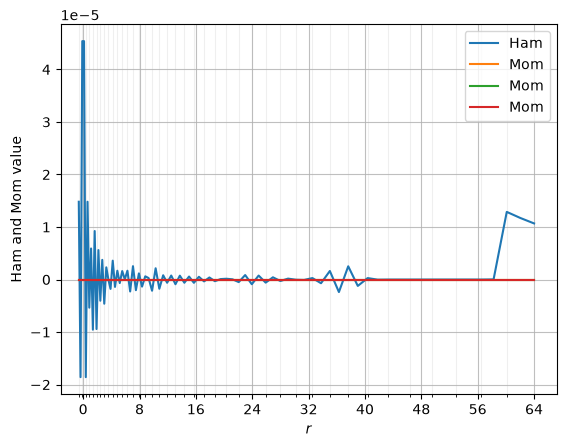

In [16]:
# check the Hamiltonian constraint initially satisfied
# apart from numerical errors
Ham, Mom = get_constraints_diagnostic(initial_state, np.array([0]), grid, background, my_matter)

# plot the profile for Ham
plt.plot(r, Ham[0], label="Ham")
plt.plot(r, Mom[0], label="Mom")

plt.xlabel('r')
plt.legend(loc="best")
#plt.xlim(-4.0,max_r)
#plt.ylim(-0.01,0.01)
plt.ylabel('Ham and Mom value')
ax = plt.gcf().gca()
set_grid_on_ax(ax, r)

In [17]:
# for control of time integrator and spatial grid
T = 10.0 # Maximum evolution time
num_points_t = 101 # time resolution (only for outputs, not for integration)

# Work out dt and time spacing of outputs
dt = T/num_points_t
t = np.linspace(0, T-dt, num_points_t)

# Solve for the solution using RK45 integration of the ODE
# to make like (older) python odeint method use method='LSODA' instead
# use tqdm package to track progress
with tqdm(total=1000, unit="‰") as progress_bar:
    dense_solution = solve_ivp(get_rhs, [0,T], initial_state, 
                               args=(grid, background, my_matter, progress_bar, [0, T/1000]),
                        #atol=1e-5, rtol=1e-5,
                        max_step = 0.4 * min_dr, #for stability and for KO coeff of 1
                        method='RK45', dense_output=True)

# Interpolate the solution at the time points defined in myparams.py
solution = dense_solution.sol(t).T

  0%|          | 0/1000 [00:00<?, ?‰/s]


TypeError: get_rhs() takes 5 positional arguments but 7 were given

In [ ]:
np.save(comparison_dir / "solution_jax.npy", np.asarray(solution))
np.save(comparison_dir / "times_jax.npy", np.asarray(t))

In [ ]:
solution_numpy = np.load(comparison_dir / "solution_numpy.npy")
solution_jax = np.load(comparison_dir / "solution_jax.npy")
times_numpy = np.load(comparison_dir / "times_numpy.npy")
times_jax = np.load(comparison_dir / "times_jax.npy")

print("Solution shapes:", solution_numpy.shape, solution_jax.shape)
print("Maximum time difference:", np.max(np.abs(times_jax - times_numpy)))

difference = np.abs(solution_jax - solution_numpy)
print("Maximum difference at first output time:", np.max(difference[1]))
print("Maximum difference at final output time:", np.max(difference[-1]))

# Report the largest difference for each variable over all output times and grid points.
difference_by_variable = difference.reshape(len(times_jax), 14, grid.N).max(axis=(0, 2))
variable_names = [
    "phi", "hrr", "htt", "hpp", "K", "arr", "att",
    "app", "lambdar", "shiftr", "br", "lapse", "u", "v",
]

for name, value in zip(variable_names, difference_by_variable):
    print(f"{name}: {value}")

Solution shapes: (101, 1134) (101, 1134)
Maximum time difference: 0.0
Maximum difference at first output time: 5.035143309239931e-15
Maximum difference at final output time: 1.050201592356359e-14
phi: 2.572811755308102e-15
hrr: 5.4626442258509655e-15
htt: 2.687086664288074e-15
hpp: 2.6766783234322133e-15
K: 3.068031939612581e-14
arr: 9.072408061808326e-15
att: 4.761474401990135e-15
app: 4.317994817634079e-15
lambdar: 2.5525588587260728e-14
shiftr: 3.646361641448936e-15
br: 1.8248423605538022e-14
lapse: 1.4432899320127035e-14
u: 9.055256544598933e-16
v: 1.7555401576885288e-15


In [ ]:
state_numpy = np.load(comparison_dir / "initial_state_numpy.npy")
state_jax = np.load(comparison_dir / "initial_state_jax.npy")
solution_numpy = np.load(comparison_dir / "solution_numpy.npy")
solution_jax = np.load(comparison_dir / "solution_jax.npy")

print(
    "NumPy initial-output difference:",
    np.max(np.abs(solution_numpy[0] - state_numpy)),
)
print(
    "JAX initial-output difference:",
    np.max(np.abs(solution_jax[0] - state_jax)),
)

NumPy initial-output difference: 0.0
JAX initial-output difference: 0.0


In [ ]:
with tqdm(total=1000, unit="‰") as progress_bar:
    rhs_initial = get_rhs(
        0.0,
        initial_state,
        grid,
        background,
        my_matter,
        progress_bar,
        [0, T / 1000],
    )
np.save(comparison_dir / "rhs_initial_jax.npy", np.asarray(rhs_initial))

  0%|          | 0/1000 [00:00<?, ?‰/s]


In [ ]:
rhs_numpy = np.load(comparison_dir / "rhs_initial_numpy.npy")
rhs_jax = np.load(comparison_dir / "rhs_initial_jax.npy")

print("RHS shapes:", rhs_numpy.shape, rhs_jax.shape)
print("Maximum RHS difference:", np.max(np.abs(rhs_jax - rhs_numpy)))

RHS shapes: (1134,) (1134,)
Maximum RHS difference: 7.554720737878995e-14


In [ ]:
rhs_numpy_2d = rhs_numpy.reshape(14, grid.N)
rhs_jax_2d = rhs_jax.reshape(14, grid.N)
rhs_difference = np.abs(rhs_jax_2d - rhs_numpy_2d)

variable_names = [
    "phi", "hrr", "htt", "hpp", "K", "arr", "att",
    "app", "lambdar", "shiftr", "br", "lapse", "u", "v",
]

for i, name in enumerate(variable_names):
    point = np.argmax(rhs_difference[i])
    print(
        f"{name}: max difference = {rhs_difference[i, point]:.8g} "
        f"at grid point {point}; "
        f"NumPy = {rhs_numpy_2d[i, point]:.8g}, "
        f"JAX = {rhs_jax_2d[i, point]:.8g}"
    )

phi: max difference = 2.3225534e-16 at grid point 14; NumPy = 1.8202618e-08, JAX = 1.8202618e-08
hrr: max difference = 2.0554408e-15 at grid point 14; NumPy = 1.6044214e-07, JAX = 1.6044215e-07
htt: max difference = 8.6357185e-16 at grid point 14; NumPy = -6.9394762e-08, JAX = -6.9394763e-08
hpp: max difference = 8.6357185e-16 at grid point 14; NumPy = -6.9394762e-08, JAX = -6.9394763e-08
K: max difference = 7.5547207e-14 at grid point 14; NumPy = 0.0046589972, JAX = 0.0046589972
arr: max difference = 7.4504205e-14 at grid point 14; NumPy = 0.0032216733, JAX = 0.0032216733
att: max difference = 3.5220091e-14 at grid point 14; NumPy = -0.0015229272, JAX = -0.0015229272
app: max difference = 3.5216838e-14 at grid point 14; NumPy = -0.0015229272, JAX = -0.0015229272
lambdar: max difference = 5.4678861e-15 at grid point 16; NumPy = 6.6484446e-07, JAX = 6.6484447e-07
shiftr: max difference = 0 at grid point 0; NumPy = -0, JAX = -0
br: max difference = 0 at grid point 0; NumPy = -0, JAX = -0

In [ ]:
from core.spacing import NUM_GHOSTS

physical = slice(NUM_GHOSTS, -NUM_GHOSTS)

for i, name in enumerate(variable_names):
    inner_ghost_diff = np.max(rhs_difference[i, :NUM_GHOSTS])
    physical_diff = np.max(rhs_difference[i, physical])
    outer_ghost_diff = np.max(rhs_difference[i, -NUM_GHOSTS:])

    print(
        f"{name}: "
        f"inner ghosts = {inner_ghost_diff:.8g}, "
        f"physical grid = {physical_diff:.8g}, "
        f"outer ghosts = {outer_ghost_diff:.8g}"
    )

phi: inner ghosts = 2.3605127e-17, physical grid = 2.3225534e-16, outer ghosts = 1.9387046e-26
hrr: inner ghosts = 1.3649258e-16, physical grid = 2.0554408e-15, outer ghosts = 1.0339758e-25
htt: inner ghosts = 4.9159172e-17, physical grid = 8.6357185e-16, outer ghosts = 5.1698788e-26
hpp: inner ghosts = 4.9159172e-17, physical grid = 8.6357185e-16, outer ghosts = 5.1698788e-26
K: inner ghosts = 1.6320278e-14, physical grid = 7.5547207e-14, outer ghosts = 1.9677517e-18
arr: inner ghosts = 6.9033321e-15, physical grid = 7.4504205e-14, outer ghosts = 5.8097527e-19
att: inner ghosts = 3.4473292e-15, physical grid = 3.5220091e-14, outer ghosts = 2.8525489e-19
app: inner ghosts = 3.4473292e-15, physical grid = 3.5216838e-14, outer ghosts = 2.8525489e-19
lambdar: inner ghosts = 1.2930869e-15, physical grid = 5.4678861e-15, outer ghosts = 3.6791339e-20
shiftr: inner ghosts = 0, physical grid = 0, outer ghosts = 0
br: inner ghosts = 0, physical grid = 0, outer ghosts = 0
lapse: inner ghosts = 1

In [ ]:
from core.spacing import NUM_GHOSTS

solution_difference = np.abs(solution_jax - solution_numpy).reshape(
    len(times_jax), 14, grid.N
)
physical = slice(NUM_GHOSTS, -NUM_GHOSTS)

for i, name in enumerate(variable_names):
    inner = np.max(solution_difference[:, i, :NUM_GHOSTS])
    physical_diff = np.max(solution_difference[:, i, physical])
    outer = np.max(solution_difference[:, i, -NUM_GHOSTS:])
    final_physical = np.max(solution_difference[-1, i, physical])

    print(
        f"{name}: inner ghosts = {inner:.8g}, "
        f"physical grid = {physical_diff:.8g}, "
        f"outer ghosts = {outer:.8g}, "
        f"final physical grid = {final_physical:.8g}"
    )

phi: inner ghosts = 2.5728118e-15, physical grid = 2.5728118e-15, outer ghosts = 3.7513395e-17, final physical grid = 6.9041994e-16
hrr: inner ghosts = 3.2189963e-15, physical grid = 5.4626442e-15, outer ghosts = 1.6132928e-16, final physical grid = 2.8137215e-15
htt: inner ghosts = 1.6290138e-15, physical grid = 2.6870867e-15, outer ghosts = 8.4134089e-17, final physical grid = 1.3530843e-15
hpp: inner ghosts = 1.6346516e-15, physical grid = 2.6766783e-15, outer ghosts = 8.0664642e-17, final physical grid = 1.3010426e-15
K: inner ghosts = 3.0680319e-14, physical grid = 3.0680319e-14, outer ghosts = 9.330286e-17, final physical grid = 1.0502016e-14
arr: inner ghosts = 9.0724081e-15, physical grid = 9.0724081e-15, outer ghosts = 4.087824e-17, final physical grid = 8.0821841e-15
att: inner ghosts = 4.7614744e-15, physical grid = 4.7614744e-15, outer ghosts = 1.9927982e-17, final physical grid = 3.8838885e-15
app: inner ghosts = 4.3179948e-15, physical grid = 4.3179948e-15, outer ghosts =

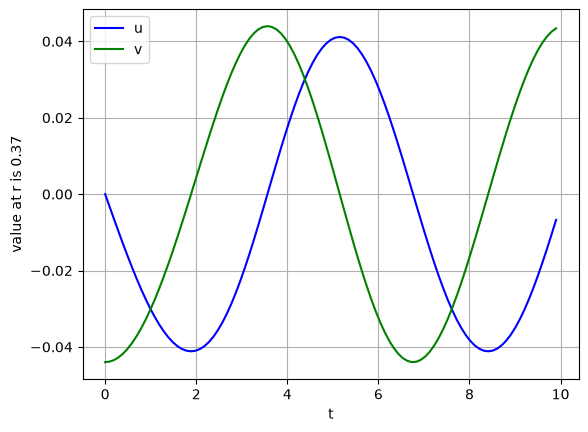

In [ ]:
# Plot a single point versus time
var1 = my_matter.idx_u
var2 = my_matter.idx_v

idx = NUM_GHOSTS+1
r_i = np.round(r[idx],2)
var1_of_t = solution[:, var1 * num_points + idx]
plt.plot(t, var1_of_t, 'b-', label=my_state_vector.VARIABLE_NAMES[var1])
var2_of_t = solution[:, var2 * num_points + idx]
plt.plot(t, var2_of_t, 'g-', label=my_state_vector.VARIABLE_NAMES[var2])
plt.legend(loc='best')
plt.xlabel('t')
plt.ylabel('value at r is '+str(r_i))
plt.legend(loc='best')
plt.grid()

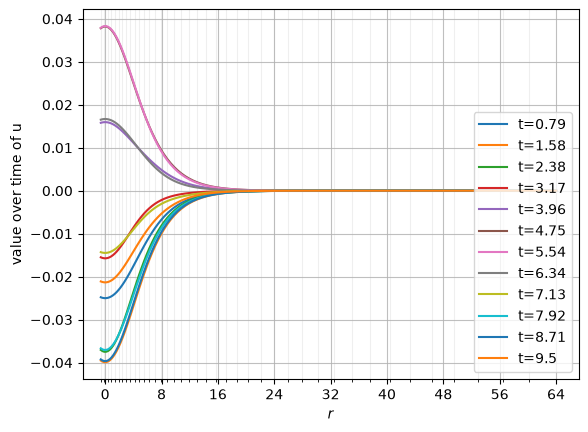

In [ ]:
# plot the profile for some variable at a selection of times
var = my_matter.idx_u # I suggest looking at the field u, or the lapse to see the gauge evolution

for i, t_i in enumerate(t) :
    if (i < num_points_t) and (i % 8 == 0) and (t_i > 0.0):
        labelt = "t="+str(round(t_i,2))
        f_t = solution[i, var * num_points: (var + 1) * num_points]
        plt.plot(r, f_t, label=labelt)

plt.legend(loc=4)
plt.xlabel('r')
plt.ylabel('value over time of ' + my_state_vector.VARIABLE_NAMES[var])
ax = plt.gcf().gca()
set_grid_on_ax(ax, r)
#plt.xlim(-0.2,40.0)
#plt.ylim(-0.001,0.001)

In [ ]:
# calculate the diagnostics, just the Hamiltonian constraint for now
Ham, Mom = get_constraints_diagnostic(solution, t, grid, background, my_matter)

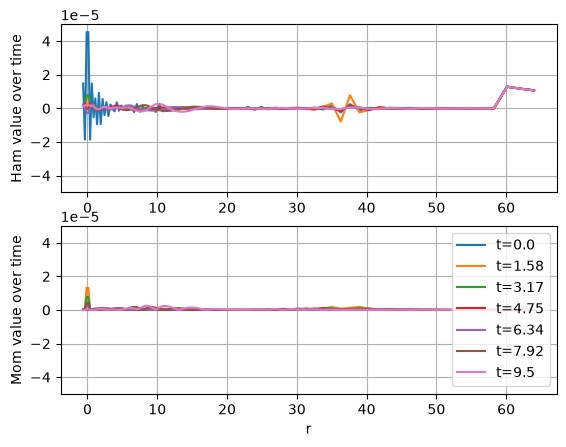

In [ ]:
# plot the profile for Ham and Mom at a selection of times

for i, t_i in enumerate(t) :
    if (i < num_points_t) and (i % 16 == 0) :
        labelt = "t="+str(round(t_i,2))
        Ham_t = Ham[i,:]
        ax1 = plt.subplot(211)
        plt.plot(r, Ham_t, label=labelt)
        ax2 = plt.subplot(212)
        Mom_t = np.sqrt(Mom[i,:,i_r]**2 + Mom[i,:,i_t]**2 + Mom[i,:,i_p]**2)
        plt.plot(r, Mom_t, label=labelt)

plt.legend()
ax2.set_xlabel('r')
ax1.set_ylabel('Ham value over time')
# ax1.set_xlim(-1,20.0)
ax1.set_ylim(-5e-5,5e-5)
ax1.grid()
ax2.set_ylabel('Mom value over time')
# ax2.set_xlim(-1,20.0)
ax2.set_ylim(-5e-5,5e-5)
ax2.grid();

In [ ]:
# Animation of the fields (u, v) varying in time
from matplotlib import animation
%matplotlib notebook

# Select variable to plot (u or v)
var_to_plot_id, var_label = my_matter.idx_u, r'$u(t,r)$'
#var_to_anim_id, var_label = my_matter.idx_uidx_v, r'$v(t,r)$'

# Pick it out of the solution vector
var_to_anim = solution[:, var_to_plot_id * num_points:var_to_plot_id * num_points + num_points]

# Set up the figure, the axis, and the plot element we want to animate
fig = plt.figure()
ax = plt.axes(xlim=(r[NUM_GHOSTS], r[-NUM_GHOSTS]), ylim=(1.1*np.min(var_to_anim), 1.1*np.max(var_to_anim)))
line, = plt.plot([], [], lw=2)
ax.set_xlabel(r'$r$')
ax.set_ylabel(var_label)

def init():
    line.set_data([], [])
    return line,

# Animation function. This is called sequentially
def animate(i):
    x = r[NUM_GHOSTS:-NUM_GHOSTS]
    y = var_to_anim[i][NUM_GHOSTS:-NUM_GHOSTS]
    line.set_data(x, y)
    return line,

# Call the animator
anim = animation.FuncAnimation(fig, animate, init_func=init, frames=np.arange(0,num_points_t,1), interval=100, blit=True)

# Display the animation interactively.
# from IPython.display import HTML
# HTML(anim.to_jshtml())

# Option to save the animation - requires a codec e.g. FFMPEG
#anim.save('./field_animation.mp4', writer = 'ffmpeg', fps = 20)

<IPython.core.display.Javascript object>